In [1]:
# ------------------------------------------------------------
# Reference case: generic apixaban vs warfarin, CHADS2 = 2, age 70,
# lifetime horizon, public payer perspective, 1.5% discounting, 2025 CAD
# ------------------------------------------------------------
import pandas as pd
from markov_model import load_inputs, run_both

p, S = load_inputs()
WTP = S["wtp"]
apx, war = run_both(p, S)

def icer_text(d_cost, d_qaly):
    """
    Report the result the way CDA-AMC does. An ICER is only meaningful when
    the new drug costs MORE and gives MORE health. Otherwise we report
    dominance, because a negative ICER is ambiguous (it can mean "cheaper
    and better" or "dearer and worse").
    """
    if d_cost <= 0 and d_qaly >= 0:
        return "Apixaban dominant (less costly, more effective)"
    if d_cost >= 0 and d_qaly <= 0:
        return "Apixaban dominated (more costly, less effective)"
    return f"${d_cost / d_qaly:,.0f} per QALY gained"

d_cost = apx["cost"] - war["cost"]
d_qaly = apx["qaly"] - war["qaly"]
d_ly = apx["ly"] - war["ly"]

# Net monetary benefit: value health in dollars, subtract cost.
# Positive = worth adopting at this willingness to pay. Unlike the ICER,
# NMB is never ambiguous, so it's what we'll use for the tornado in Step 7.
inmb = d_qaly * WTP - d_cost

print(f"Incremental cost : ${d_cost:,.0f}")
print(f"Incremental QALYs: {d_qaly:.3f}")
print(f"Incremental LYs  : {d_ly:.3f}")
print(f"Result           : {icer_text(d_cost, d_qaly)}")
print(f"Incremental net monetary benefit at ${WTP:,}/QALY: ${inmb:,.0f}")

Incremental cost : $-5,608
Incremental QALYs: 0.236
Incremental LYs  : 0.258
Result           : Apixaban dominant (less costly, more effective)
Incremental net monetary benefit at $50,000/QALY: $17,421


In [2]:
# ------------------------------------------------------------
# Disaggregated results, laid out like CADTH worked example Table 3
# ------------------------------------------------------------
def column(r):
    return [r["cost_undisc"], r["qaly_undisc"], r["ly_undisc"],
            r["cost"], r["cost_drug"], r["cost_event"], r["cost_lt"],
            r["qaly"], r["ly"], r["qaly"] * WTP - r["cost"]]

table = pd.DataFrame(
    {"Apixaban": column(apx), "Warfarin": column(war)},
    index=["Undiscounted: total cost", "Undiscounted: QALYs", "Undiscounted: life-years",
           "Discounted: total cost", "   drug + monitoring", "   clinical events",
           "   long-term stroke care", "Discounted: QALYs", "Discounted: life-years",
           f"Net monetary benefit (${WTP:,}/QALY)"])
table["Incremental"] = table["Apixaban"] - table["Warfarin"]

pd.set_option("display.float_format", "{:,.3f}".format)
print(table)
table.to_csv("../outputs/reference_case_table.csv")

                                       Apixaban    Warfarin  Incremental
Undiscounted: total cost             25,757.486  31,951.543   -6,194.058
Undiscounted: QALYs                       8.225       7.944        0.281
Undiscounted: life-years                 10.352      10.043        0.309
Discounted: total cost               22,807.847  28,415.756   -5,607.909
   drug + monitoring                  2,362.097   2,791.203     -429.106
   clinical events                   11,499.738  13,952.852   -2,453.114
   long-term stroke care              8,946.012  11,671.701   -2,725.689
Discounted: QALYs                         7.464       7.228        0.236
Discounted: life-years                    9.388       9.129        0.258
Net monetary benefit ($50,000/QALY) 350,415.406 332,993.977   17,421.428


In [3]:
# ------------------------------------------------------------
# At what apixaban price does the conclusion change?
# The drug price enters the model in only one place (cost in S0), and
# time spent in S0 doesn't depend on price, so incremental cost is a
# STRAIGHT LINE in price. Two model runs give the whole line exactly.
# ------------------------------------------------------------
def d_cost_at(price_per_tablet):
    q = dict(p)
    q["c_apixaban"] = price_per_tablet * 2 * 365.25      # 5 mg twice daily
    a, w = run_both(q, S)
    return a["cost"] - w["cost"]

p_lo, p_hi = 0.40, 1.60
c_lo, c_hi = d_cost_at(p_lo), d_cost_at(p_hi)
slope = (c_hi - c_lo) / (p_hi - p_lo)          # extra $ per $1 on the tablet price

# Solve the line for the two prices that matter
price_neutral = p_lo + (0 - c_lo) / slope                  # incremental cost = 0
price_at_wtp = p_lo + (d_qaly * WTP - c_lo) / slope        # ICER = WTP

print(f"Each $0.10 per tablet adds ${slope*0.10:,.0f} to the incremental cost")
print(f"Price at which apixaban is cost-NEUTRAL vs warfarin : ${price_neutral:.4f} per tablet")
print(f"Price at which ICER = ${WTP:,}/QALY               : ${price_at_wtp:.4f} per tablet")
print(f"Current generic price 0.4084 = {0.4084/price_neutral:.0%} of cost-neutral price")
brand = d_cost_at(1.6336)
print(f"Brand price 1.6336: incremental cost ${brand:,.0f}, ICER ${brand/d_qaly:,.0f}")

# Prove the line really is straight: a third point must fall exactly on it
print(f"check linear: {d_cost_at(1.0):.4f} vs {c_lo + slope*0.6:.4f}")

Each $0.10 per tablet adds $562 to the incremental cost
Price at which apixaban is cost-NEUTRAL vs warfarin : $1.4059 per tablet
Price at which ICER = $50,000/QALY               : $3.5072 per tablet
Current generic price 0.4084 = 29% of cost-neutral price
Brand price 1.6336: incremental cost $1,280, ICER $5,419
check linear: -2281.8918 vs -2281.8918


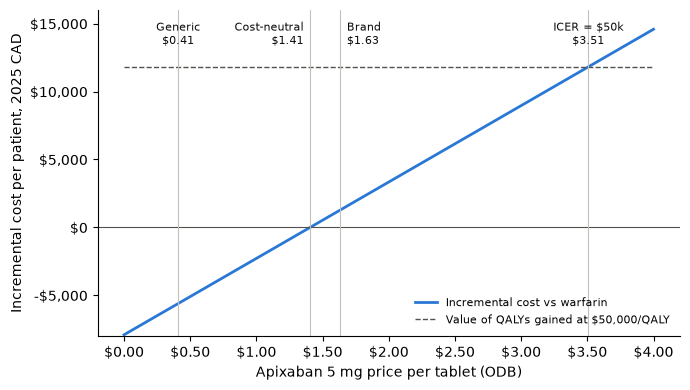

In [4]:
# ------------------------------------------------------------
# One picture of the whole price story
# ------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

prices = np.linspace(0, 4, 81)
inc_cost = c_lo + slope * (prices - p_lo)       # the straight line from Cell 3

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prices, inc_cost, color="#2a78d6", lw=2, label="Incremental cost vs warfarin")
ax.plot(prices, np.full_like(prices, d_qaly * WTP), color="#52514e", lw=1, ls="--",
        label=f"Value of QALYs gained at ${WTP:,}/QALY")
ax.axhline(0, color="#52514e", lw=0.8)

# Vertical markers. Two of them sit close together, so their labels
# are pushed apart (one right-aligned, one left-aligned).
markers = [(0.4084, "Generic\n$0.41", "center"),
           (price_neutral, f"Cost-neutral\n${price_neutral:.2f}", "right"),
           (1.6336, "Brand\n$1.63", "left"),
           (price_at_wtp, f"ICER = $50k\n${price_at_wtp:.2f}", "center")]
for x, lab, align in markers:
    ax.axvline(x, color="#c3c2b7", lw=0.8)
    nudge = {"center": 0, "right": -0.05, "left": 0.05}[align]
    ax.text(x + nudge, 13500, lab, ha=align, fontsize=8, color="#0b0b0b")

ax.set_xlabel("Apixaban 5 mg price per tablet (ODB)")
ax.set_ylabel("Incremental cost per patient, 2025 CAD")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:.2f}"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda v, _: f"-${-v:,.0f}" if v < 0 else f"${v:,.0f}"))
ax.set_ylim(-8000, 16000)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/fig_price_threshold.png", dpi=150)
plt.show()

In [5]:
# ------------------------------------------------------------
# Save for the report, the README and the Excel cross-check (Step 9)
# ------------------------------------------------------------
import json

headline = {
    "d_cost": d_cost, "d_qaly": d_qaly, "d_ly": d_ly,
    "result": icer_text(d_cost, d_qaly), "inmb_at_wtp": inmb,
    "apixaban_cost": apx["cost"], "warfarin_cost": war["cost"],
    "apixaban_qaly": apx["qaly"], "warfarin_qaly": war["qaly"],
    "price_cost_neutral_per_tablet": price_neutral,
    "price_icer_equals_wtp_per_tablet": price_at_wtp,
    "brand_icer": brand / d_qaly,
}
with open("../outputs/reference_case.json", "w") as f:
    json.dump(headline, f, indent=2)
print("Saved reference_case.json")

Saved reference_case.json
